In [ ]:
import zipfile
zip_ref = zipfile.ZipFile("/content/cat vs dog.zip", 'r')
zip_ref.extractall()
zip_ref.close()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
#normalizing
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
#generator
train_data = train_datagen.flow_from_directory(
    r"/content/dataset/training_set",
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

val_data = val_datagen.flow_from_directory(
    r"/content/dataset/test_set",
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.


In [ ]:
#making cnn model
model = Sequential()
model.add(Conv2D(32,(3,3),padding='valid',activation='relu',input_shape = (224,224,3)))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(64,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(128,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,281 (42.64 MB)

 Trainable params: 11,177,281 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(train_data,epochs=10,validation_data=val_data)
history

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 115s 428ms/step - accuracy: 0.5271 - loss: 0.7489 - val_accuracy: 0.5995 - val_loss: 0.6525
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 102s 408ms/step - accuracy: 0.5970 - loss: 0.6556 - val_accuracy: 0.6770 - val_loss: 0.6141
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 103s 412ms/step - accuracy: 0.6547 - loss: 0.6213 - val_accuracy: 0.6820 - val_loss: 0.5808
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 102s 410ms/step - accuracy: 0.6985 - loss: 0.5736 - val_accuracy: 0.7165 - val_loss: 0.5423
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 101s 405ms/step - accuracy: 0.7185 - loss: 0.5441 - val_accuracy: 0.7670 - val_loss: 0.4854
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 141s 400ms/step - accuracy: 0.7606 - loss: 0.4914 - val_accuracy: 0.7810 - val_loss: 0.4691
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 101s 403ms/step - accuracy: 0.7888 - loss: 0.4527 - val_accuracy: 0.7550 - val_loss: 0.4916
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 101s 403ms/step - accuracy: 0.7826 -

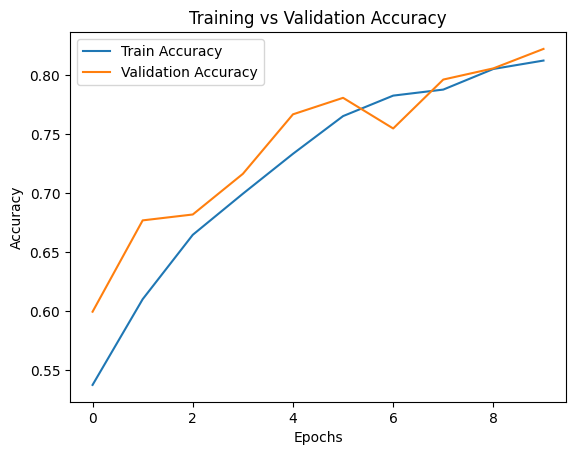

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

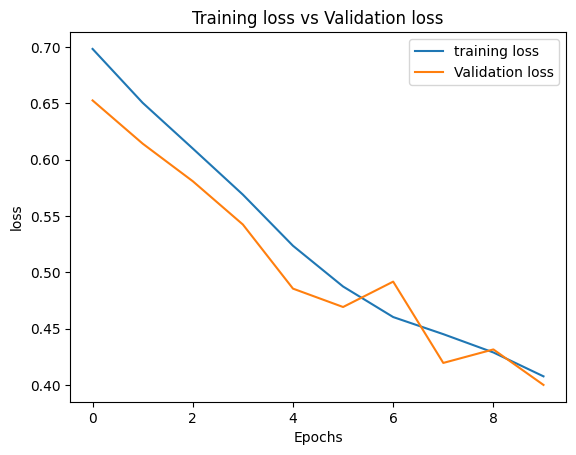

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.title('Training loss vs Validation loss')
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# 1. Load image
img_path = r"/content/dataset/test_set/dogs/dog.4003.jpg"
img = image.load_img(img_path, target_size=(224, 224))

# 2. Convert to array
img_array = image.img_to_array(img)

# 3. Normalize (same as training)
img_array = img_array / 255.0

# 4. Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# 5. Predict
prediction = model.predict(img_array)

# 6. Interpret result
if prediction[0][0] > 0.5:
    print("It is a Dog 🐶")
else:
    print("It is a Cat 🐱")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
It is a Dog 🐶


In [ ]:
model.save('cat_dog_classifier.h5')